# 网页制作

学成在线（前端第07天）


本日把前面学过的 HTML、选择器、盒子模型、浮动与清除浮动用于一个完整页面：学成在线首页。课件先讲项目目录与布局流程，课堂源码再从头部向下实现各区域。

资料来自 `day07-学成在线项目.rar`：`day07（网页制作）v1.0.pdf`（5页）、`学成网首页.psd` 和 `study` 项目。课件篇幅短，具体尺寸、选择器与内容以随包提供的 `study/index.html`、`study/css/index.css` 为依据。本日资料没有 XMind 或独立作业目录。

本篇先保留原课的目录与布局方法，再按源码顺序拆解头部、横幅、兴趣推荐、课程卡片和页脚。设计稿里的其他课程模块没有出现在课堂源码中，阅读时要区分设计目标与当前实现。

代码均用于阅读，不设置执行单元。HTML 片段写入 `study/index.html`，CSS 片段按顺序写入 `study/css/index.css`；配套图片保留在 `study/images`。各节代码直接摘录原文件，注释中的替换方案不视为当前启用效果。


## 1. 创建项目根目录

课件第3页先确定文件放在哪里，再连接 HTML、CSS 与图片。


### 1.1 根目录与实际文件结构

根目录是网站的第一级文件夹。本项目的根目录名为 `study`，其实际结构为：

```text
study/
├─ index.html
├─ css/
│  └─ index.css
└─ images/
   ├─ logo.png
   ├─ user.png
   ├─ btn.png
   ├─ banner2.png
   ├─ course01.png … course08.png
   └─ 其他课程图片素材
```

`index.html` 负责首页结构，`css/index.css` 负责首页样式，`images` 放图片。目录位置对应原压缩包的 `day07/01-案例/study`；设计稿 `学成网首页.psd` 在它的上一级目录。

课件列表把样式文件夹写为“CSS”，但课件代码和实际项目使用小写 `css`。练习时跟随实际路径写小写，避免搬到区分大小写的环境后加载失败。

原 HTML 注释说“所有网站的首页都叫 index.html，服务器找首页都是找 index.html”。补充：`index.html` 是本项目采用的常见默认首页名，服务器默认首页可以配置，不能把这句课堂简写理解成所有网站的硬性规则。


### 1.2 在 HTML 中引入外部样式

课件原图：

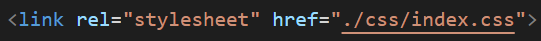

在 `study/index.html` 的 `<head>` 中，通过 `link` 引入样式表。原文件头部如下：

```html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>学成在线</title>
    <link rel="stylesheet" href="./css/index.css">
</head>
```

`rel="stylesheet"` 表示样式表，`href="./css/index.css"` 从当前 HTML 文件所在目录进入 `css` 文件夹。

完成后打开 `index.html`，应看到 CSS 控制的浅灰页面背景、版心和各模块布局。如果仍是普通上下排列的文字与图片，先确认 `link` 路径、文件名和大小写，再检查样式是否成功加载。


### 1.3 HTML 与 CSS 中的图片路径不同

| 写在哪里 | 原源码写法 | 路径从哪里出发 |
| --- | --- | --- |
| `index.html` 的图片标签 | `src="./images/logo.png"` | 从 `study/index.html` 所在目录出发 |
| `css/index.css` 的背景图 | `url(../images/banner2.png)` | 从 CSS 文件所在的 `study/css` 出发，先回到 `study` |

因此不能把 CSS 的 `../images/...` 直接抄成 HTML 中的路径，也不能只搬走 `index.html` 而丢掉 `css`、`images`。

当前源码直接使用5张图片：`logo.png`（195×42px）、`user.png`（30×30px）、`btn.png`（50×40px）、`banner2.png`（1200×420px）、`course07.png`（228×155px）。课程素材还有 `course01.png` 至 `course08.png`、`pic.png`、`left.jpg`、`top.jpg` 与 `bottom01.jpg` 至 `bottom04.jpg`，但这些其他素材没有全部用于当前页面。


## 2. 布局流程与公共样式

课件第4页要求从外到内、从上到下布局。先确定盒子的范围和位置，再放内容、调整文字细节。


### 2.1 先对照整张设计稿，明确课堂实现范围

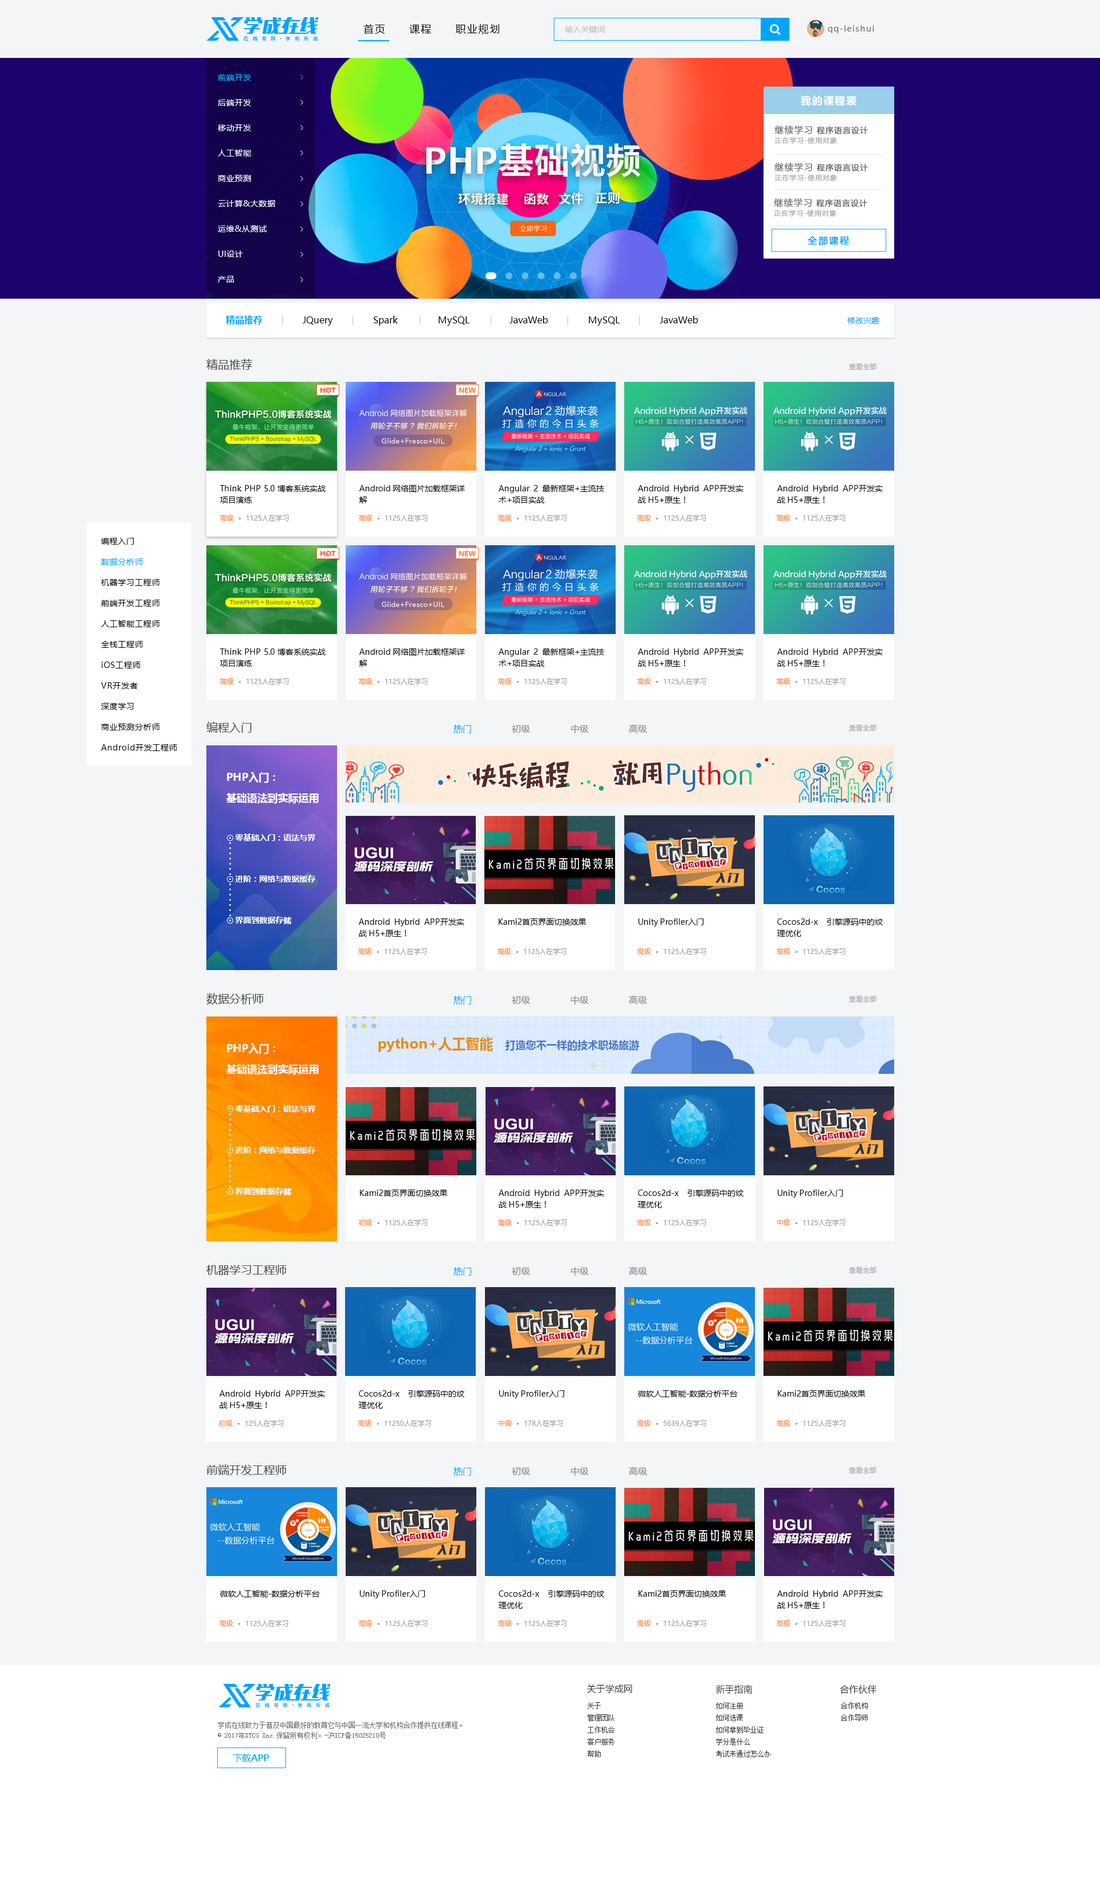

设计稿中有顶部导航、横幅、兴趣推荐、精品课程、编程入门、数据分析师、机器学习工程师、前端开发工程师、侧边分类和页脚。

随包的课堂源码实现了其中的头部、横幅、兴趣推荐、一组10张精品课程卡片和页脚。左侧横幅菜单全部写为“前端开发”，推荐条全部写为 `jQuery`，10张卡片使用同一图片与文字，页脚重复3组“合作伙伴”。这些是源码当前内容，不等同于设计稿里的多样化内容。

页面标题、搜索按钮与链接也只是静态结构：源码没有 JavaScript，没有真正的课程搜索、轮播切换、兴趣修改或 APP 下载逻辑。笔记按本日的网页制作范围讲解布局。


### 2.2 原课布局步骤：外层定位后再处理内容

按课件与源码注释的顺序：

1. 从外到内、从上到下拆分区域；同一区域再从左到右放子盒子。
2. 先写宽度、高度与背景色，确认区域范围。
3. 调整位置：普通流版心居中，内部同排区域用浮动，间隔通过外边距处理。
4. 放入文字、图片、列表与表单控件。
5. 调整内容位置：内边距、行高、文字对齐等。
6. 最后检查字号、颜色、边框、阴影和悬停样式。

源码沿用“浮动/display → 盒子模型 → 文字样式”的声明组织方式，方便从布局到细节依次检查。练习时不要只照着一段段属性抄，要知道每组属性负责哪个盒子。


### 2.3 重置样式、内减模式与 clearfix

以下是 `study/css/index.css` 的开头：

```css
/* index.css是用来美化首页的 */
* {
    margin: 0;
    padding: 0;
    /* 內减模式 */
    box-sizing: border-box;
}

li {
    list-style: none;
}
a {
    text-decoration: none;
}

.clearfix:before,.clearfix:after {
    content:"";
    display:table; 
  }
  .clearfix:after {
    clear:both;
  }


body {
    background-color: #f3f5f7;
}
```

| 公共规则 | 本项目用途 |
| --- | --- |
| `margin: 0; padding: 0` | 去掉标签默认间距，便于按设计尺寸布局 |
| `box-sizing: border-box` | 元素指定宽高时，把边框和内边距算在这个尺寸内 |
| `li { list-style: none }` | 去掉导航、菜单和课程列表的小圆点 |
| `a { text-decoration: none }` | 去掉链接默认下划线，文字颜色在各区域单独设置 |
| `.clearfix` 的双伪元素 | 处理课程卡片浮动对子级容纳和后续页脚位置的影响 |
| `body` 背景 `#f3f5f7` | 形成页面整体浅灰背景 |

源码的双伪元素采用 `:before`、`:after` 单冒号写法，这是这里保留的原代码；第06天笔记使用的 `::before`、`::after` 双冒号形式表达同一类伪元素。不要因写法差异漏掉 `content`、`display` 或 `clear`。

本项目没有统一设置 `font-family` 或全局字号，未单独声明的文字继续使用浏览器默认或继承来的样式。截图中的字体外观不能全部归因于这份 CSS。


### 2.4 版心类只负责公共宽度和水平居中

```css
/* 版心 */
.wrapper {
    width: 1200px;
    margin: 0 auto;
}
```

`.wrapper` 将区域宽度固定为1200px，再用 `margin: 0 auto` 把普通流块盒子水平居中。它不承担头部高度、横幅背景或课程卡片样式，这些职责交给各区域自己的类。

例如 `class="header wrapper"` 同时获得头部样式和版心效果；横幅、页脚使用通栏外盒子，在内部另放 `.wrapper`。

这个页面使用固定1200px版心。窗口宽度不足1200px时，不能期待它自动缩成手机布局；观察布局时先使用能容纳版心的窗口。


## 3. 头部：标志、导航、搜索与用户

头部是一排内容。先通过共同父盒子确定版心与高度，再分别安排左右浮动和间距。


### 3.1 头部结构与标志

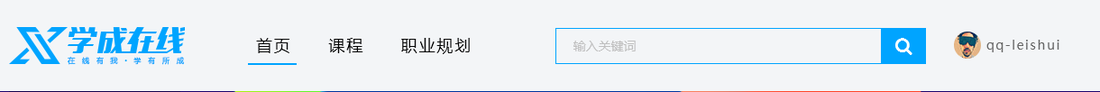

`study/index.html` 的头部结构：

```html
<!-- 网站的首页, 所有网站的首页都叫index.html, 因为服务器找首页都是找index.html -->
<!-- 布局: 从外到内, 从上到下, 从左到右 -->
<!-- CSS: 浮动/display ; 盒子模型; 文字样式 -->

<!-- 头部header: 负责头部区域的样式, wrapper只负责版心效果 -->
<div class="header wrapper">
    <h1>
        <a href="#"><img src="./images/logo.png" alt=""></a>
    </h1>

    <!-- 导航 -->
    <div class="nav">
        <ul>
            <li><a href="#">首页</a></li>
            <li><a href="#">课程</a></li>
            <li><a href="#">职业规划</a></li>
        </ul>
    </div>
    <!-- 搜索 -->
    <div class="search">
        <input type="text" placeholder="输入关键词"><button></button>
    </div>
    <!-- 用户 -->
    <div class="user">
        <img src="./images/user.png" alt="">
        <span>lilei</span>
    </div>
</div>
```

头部外盒子和标志对应的 CSS：

```css
/* 头部 */
.header {
    height: 42px;
    /* margin-top: 30px;
    margin-bottom: 30px; */
    margin: 30px auto;
}

h1 {
    float: left;
}
```

`.header` 高42px，`margin: 30px auto` 设置上下各30px、水平自动外边距。它与 `.wrapper` 的选择器权重相同，但在其后出现，因此头部上下外边距采用30px，宽度仍来自 `.wrapper` 的1200px。

标志放在 `h1 > a > img` 中，图片按原始195×42px尺寸显示；`h1` 左浮动，让导航可以排在它右边。链接 `href="#"` 是演示占位，`alt=""` 也是源文件的当前写法。

父盒子已明确给出42px高度，因此头部在普通流中有高度，即使内部多个盒子浮动，也不会像第06天的自动高度父盒子一样直接变为0。


### 3.2 导航：用内边距适应不同字数

```css
/* 导航 */
.nav {
    float: left;
    margin-left: 70px;
    height: 42px;
}

.nav li {
    float: left;
    margin-right: 26px;
}

.nav li a {
    display: block;
    padding: 0 9px;
    height: 42px;
    line-height: 42px;
    /* border-bottom: 2px solid #00a4ff; */

    font-size: 18px;
    color: #050505;
}

.nav li a:hover {
    border-bottom: 2px solid #00a4ff;
}
```

`.nav` 向左浮动，左外边距70px与标志拉开距离。内部 `li` 再向左浮动，各项保留26px右外边距。

`a` 转为块级，设置左右9px内边距，不指定固定宽度，所以“首页”“课程”“职业规划”会随文字长度形成不同宽度。42px高度配合42px行高让单行文字在竖直方向居中。

普通状态的底边框声明已注释；当前只在 `:hover` 时出现2px蓝色底边框。全局内减模式使边框计入42px高度，链接总高度不会简单增加到44px。

验证时把鼠标移到各链接上，确认蓝色底线出现，再移开确认底线消失。设计图里的“首页”常亮效果并没有用独立的当前项类在这份源码中实现。


### 3.3 搜索框：先算父级内容宽度

原按钮图片：

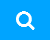

```css
/* 搜索 */
.search {
    float: left;
    margin-left: 59px;
    width: 412px;
    height: 40px;
    border: 1px solid #00a4ff;
}

.search input {
    float: left;
    padding-left: 20px;
    /* 左右加一起的尺寸要小于等于410 */
    width: 360px;
    height: 38px;
    border: 0;
}

/* 控制placeholder的样式 */
.search input::placeholder {
    font-size: 14px;
    color: #bfbfbf;
}

.search button {
    float: left;
    width: 50px;
    height: 40px;
    background-image: url(../images/btn.png);
    border: 0;
}
```

搜索区域左浮动，距前面导航59px，总宽412px、高40px，四周1px蓝色边框。

因为是 `border-box`：

```text
搜索外盒子总宽：412px
内部内容宽度：412 - 1 - 1 = 410px
输入框总宽 + 按钮总宽：360 + 50 = 410px
```

输入框的20px左内边距包含在360px之内，不能再把它加到360px外面。输入框与按钮都浮动，宽度刚好填满父内容区；若误把二者总宽写成412px，可能把按钮挤到下一行。

背景图路径 `../images/btn.png` 从 CSS 文件目录出发。按钮本身没有文字，蓝色底和白色放大镜来自50×40px的素材。

高度方面，搜索父盒子40px包含上下各1px边框，所以内容区高38px，输入框也写38px；原按钮写40px，比内容区高2px。这里保留源文件的尺寸，不能描述成两者都严丝合缝地放进38px内容高度，也不要默默改成另一版实现。


### 3.4 placeholder 与用户图片的垂直对齐

搜索输入框的 HTML 使用 `placeholder="输入关键词"`。上一节中的 `input::placeholder` 选中这段提示文字，设置14px字号和浅灰色；它不表示用户输入的真实内容也自动变成这个颜色。输入文字后提示消失，可以观察到两者的区别。

用户区域 CSS：

```css
.user {
    float: right;
    margin-right: 35px;
    height: 42px;
    line-height: 42px;
}
.user img {
    /* 调节图片垂直对齐方式, middle:居中 */
    vertical-align: middle;
}
```

`.user` 右浮动，右外边距35px，42px行高配合头部高度。30×30px头像与 `span` 文字处于同一行，`vertical-align: middle` 调整头像相对同一行文字的对齐方式，避免只按默认基线对齐时显得下沉。

补充：`middle` 调的是行内图片与文字的关系，不是一个让任何块盒子在父级中绝对居中的属性。当前用户名为 `lilei`，与设计图中的名字不同，按 HTML 源码理解效果。


## 4. 横幅：通栏背景、侧边菜单与课程表

源码注释将这一块称作“轮播图”。当前通过一个背景图实现静态横幅，再把左右两个内容盒子排在版心内。


### 4.1 外层通栏与内部背景图

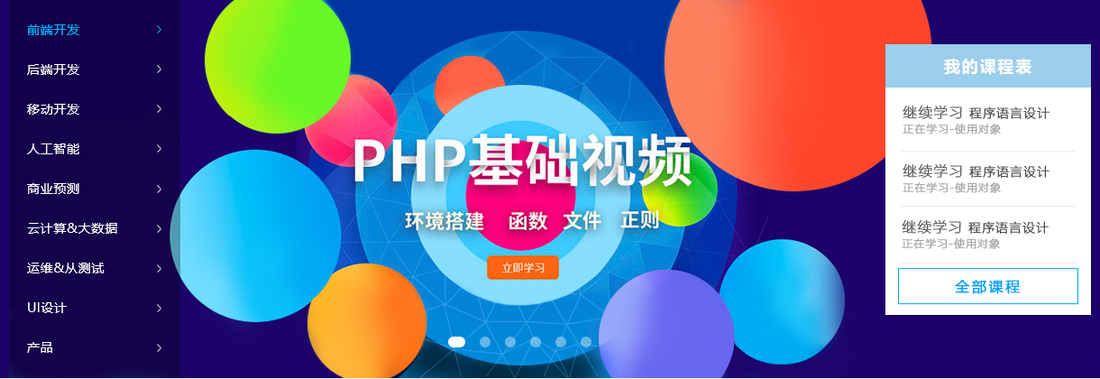

横幅完整 HTML：

```html
<!-- 轮播图banner -->
<div class="banner">
    <div class="wrapper">
        <div class="left">
            <ul>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
                <li><a href="#">前端开发<span>></span></a></li>
            </ul>
        </div>
        <div class="right">
            <h2>我的课程表</h2>
            <div class="content">
                <dl>
                    <dt>继续学习 程序语言设计</dt>
                    <dd>正在学习-使用对象</dd>
                </dl>
                <dl>
                    <dt>继续学习 程序语言设计</dt>
                    <dd>正在学习-使用对象</dd>
                </dl>
                <dl>
                    <dt>继续学习 程序语言设计</dt>
                    <dd>正在学习-使用对象</dd>
                </dl>
            </div>
            <a href="#" class="more">全部课程</a>
        </div>
    </div>
</div>
```

外层和版心对应的 CSS：

```css
/* 轮播图 */
.banner {
    height: 420px;
    background-color: #1c036c;
}

.banner .wrapper {
    height: 420px;
    background-image: url(../images/banner2.png);
}
```

外层 `.banner` 高420px，深紫色 `#1c036c` 形成通栏背景；内部 `.wrapper` 继承公共1200px宽度，并设置420px高度、`banner2.png` 背景图。

原背景素材为1200×420px，与内部盒子尺寸对应，因此这里没有另写缩放或居中属性。图片出现在 CSS 背景中，左右菜单与课程表则是独立 HTML 内容，不是把整张设计图直接当页面。

当前源码没有自动切换图片的逻辑，也没有独立编写轮播圆点或中央学习按钮的交互。横幅素材中的视觉内容不能等同于已经实现了对应功能。


### 4.2 左侧分类菜单：内边距与透明背景

```css
.banner .left {
    float: left;

    padding: 0 20px;

    width: 190px;
    height: 420px;
    background-color: rgba(0,0,0, 0.3);

    /* 行高属于控制文字的属性, 能继承 */
    line-height: 44px;
}

.banner .left span {
    float: right;
}

.banner .left a {
    font-size: 14px;
    color: #fff;
}

.banner .left a:hover {
    color: #00b4ff;
}
```

左侧宽190px、高420px、向左浮动。左右各20px内边距包含在190px内，因此内容宽度为 `190 - 20 × 2 = 150px`。

`rgba(0,0,0, 0.3)` 是30%不透明度的黑色背景，叠加在横幅图片上形成较深的分类区域。透明作用于背景颜色，链接文字仍使用白色，不会一起变成30%不透明度。

父盒子的44px行高会被内部文本继承。HTML 有9个列表项，因此文字行区域大致使用 `9 × 44 = 396px`，低于420px；源码没有把9行均分成420px。

每个链接中的 `span` 向右浮动，把 `>` 放到菜单内容区右侧。链接悬停变为 `#00b4ff`。当前9项名称均为“前端开发”，没有逐项填入设计图中的不同分类。


### 4.3 右侧课程表：标题、描述列表与按钮

```css
.banner .right {
    float: right;
    margin-top: 50px;
    width: 228px;
    height: 300px;
    background-color: #fff;
}

.banner .right h2 {
    height: 48px;
    background-color: #9bceea;
    text-align: center;
    line-height: 48px;
    font-size: 18px;
    color: #fff;
}

.banner .right .content {
    padding: 0 18px;
}

.banner .right .content dl {
    padding: 12px 0;
    border-bottom:2px solid #e5e5e5;
}

.banner .right .content dt {
    font-size: 16px;
    color: #4e4e4e;
}

.banner .right .content dd {
    font-size: 14px;
    color: #4e4e4e;
}

.banner .right .more {
    display: block;
    /* margin: 4px 14px 0; */
    margin: 4px auto 0;
    width: 200px;
    height: 40px;
    border: 1px solid #00a4ff;

    font-size: 16px;
    color: #00a4ff;
    font-weight: 700;

    text-align: center;
    line-height: 40px;
}
```

右侧课程表向右浮动，宽228px、高300px，上外边距50px，因此从横幅顶部向下50px开始；它不是通过与左侧菜单相同高度自动居中得到的位置。

| 部分 | 结构与样式用途 |
| --- | --- |
| `h2` | 48px高浅蓝标题条，18px白字居中 |
| `.content` | 左右18px内边距，使课程条目离开白盒子边缘 |
| 3组 `dl > dt + dd` | 标题与说明组成一条课程记录，`dl` 上下12px内边距、2px底边框 |
| `.more` | 转为块级的“全部课程”链接，200×40px，蓝色边框、蓝字加粗 |

`.more` 的 `margin: 4px auto 0` 表示上4px、左右自动、下0；这个链接没有浮动，因此可以用固定宽度与自动水平外边距在228px父盒子中居中。原来 `margin: 4px 14px 0` 的方案已注释。

验证时检查左右菜单是否贴合版心两侧，课程表是否距横幅顶部50px，标题与链接文字是否居中。课程记录数量与文字都来自 HTML，CSS 不会自动读取学习进度。


## 5. 精品推荐条

横幅下方是一条白底推荐区域，继续在1200px版心里安排左标题、中间列表和右侧链接。


### 5.1 结构与横向排列

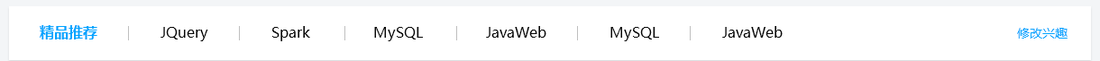

```html
<!-- 精品推荐 -->
<div class="goods wrapper">
    <h2>精品推荐</h2>
    <ul>
        <li><a href="#">jQuery</a></li>
        <li><a href="#">jQuery</a></li>
        <li><a href="#">jQuery</a></li>
        <li><a href="#">jQuery</a></li>
        <li><a href="#">jQuery</a></li>
        <li><a href="#">jQuery</a></li>
    </ul>
    <a href="#" class="xingqu">修改兴趣</a>
</div>
```

对应 CSS：

```css
/* 精品推荐 */
.goods {
    margin-top: 8px;
    padding-left: 34px;
    padding-right: 26px;

    height: 60px;
    background-color: #fff;
    box-shadow: 0px 2px 3px 0px 
		rgba(118, 118, 118, 0.2);

    line-height: 60px;

}

.goods h2 {
    float: left;
    font-size: 16px;
    color: #00a4ff;
    font-weight: 400;
}

.goods ul {
    float: left;
    margin-left: 30px;
}

.goods ul li {
    float: left;
}

.goods li a {
    border-left: 1px solid #bfbfbf;
    padding: 0 30px;
    font-size: 16px;
    color: #050505;
}

.goods .xingqu {
    float: right;
    font-size: 14px;
    color: #00a4ff;
}
```

`.goods` 与 `.wrapper` 同时作用，宽1200px、高60px，上外边距8px，左右内边距分别34px、26px。由于是内减模式，这些内边距包含在1200px总宽里，内部可用宽度为1140px。

标题、`ul` 向左浮动，`ul` 左外边距30px；各 `li` 向左浮动；“修改兴趣”向右浮动。60px行高在父级设置后向子级文字继承，使一行内容处于条形区域中间。

每个推荐链接用1px左边框形成分隔线，左右各30px内边距留出空隙。源码没有给它们统一固定宽度，也没有把推荐列表改成设计图里的不同名称；当前6项都是 `jQuery`。


### 5.2 盒子阴影的参数与布局影响

原 `.goods` 声明中有：

```css
box-shadow: 0px 2px 3px 0px
    rgba(118, 118, 118, 0.2);
```

这是同一条 CSS 声明，换行只用于书写。四个长度依次是水平偏移0px、垂直偏移2px、模糊半径3px、扩展距离0px，最后是灰色且20%不透明度的颜色。

补充：阴影属于绘制效果，不把 `.goods` 的布局高度从60px加成65px。检查横幅到推荐条的距离时，应看8px外边距，而不是把阴影模糊范围当作盒模型尺寸。

当前“修改兴趣”的 `href="#"` 仍是占位链接，点击不会弹出真正的兴趣设置界面。


## 6. 精品课程：五列卡片与清除浮动

课程区域先做标题行，再让10张卡片按每行5张排列。这里集中运用宽度计算、结构伪类与清除浮动。


### 6.1 标题行与完整 HTML

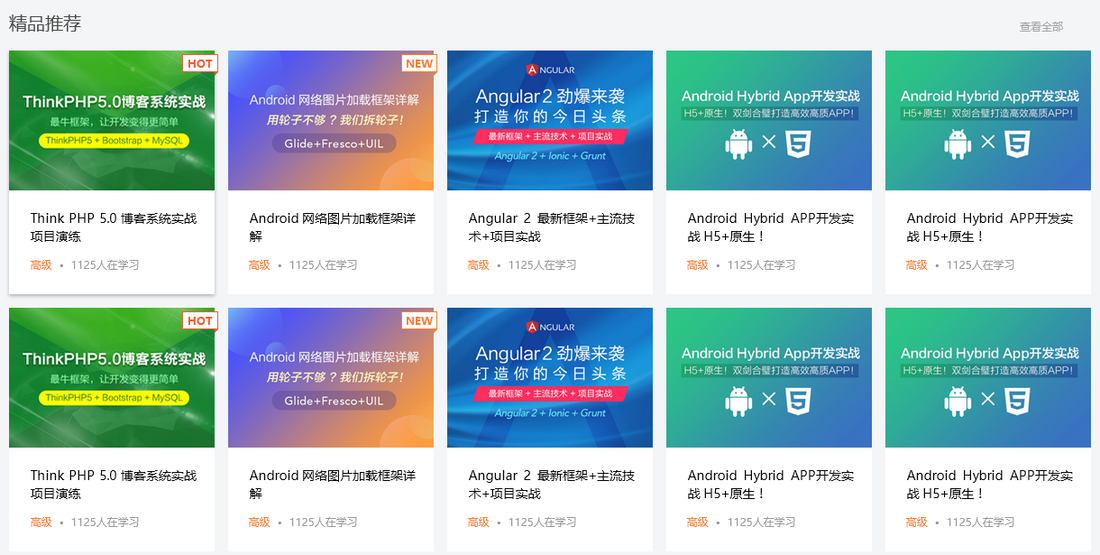

原课程区域 HTML 保留全部10张卡片：

```html
<!-- 精品推荐课程 -->
<div class="box wrapper">
    <div class="title">
        <h2>精品推荐</h2>
        <a href="#">查看全部</a>
    </div>

    <div class="content clearfix">
        <ul>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>
            <li>
                <a href="#">
                    <img src="./images/course07.png" alt="">
                    <h3>Think PHP 5.0 博客系统实战项目演练</h3>
                    <p><span>高级</span>  •  1125人在学习</p>
                </a>
            </li>

        </ul>
    </div>
</div>
```

区域与标题 CSS：

```css
/* 精品课程 */
.box {
    margin-top: 35px;
}

.box .title {
    height: 40px;
}

.box .title h2 {
    float: left;
    font-size: 20px;
    color: #494949;
    font-weight: 400;
}

.box .title a {
    float: right;
    margin-right: 30px;
    font-size: 12px;
    color: #a5a5a5;
}
```

`.box` 在版心基础上加35px上外边距。标题行高40px，标题向左浮动、20px灰字，去掉标题默认加粗；“查看全部”向右浮动，右外边距30px、12px浅灰字。

标题行有固定高度，下面的卡片内容区域则没有固定高度。这一差异决定了卡片区域需要特别处理浮动影响。


### 6.2 五列宽度：为什么要清除每第5项的右外边距

课程列表的 CSS：

```css
.box .content li {
    float: left;
    margin-right: 15px;
    margin-bottom: 15px;
    width: 228px;
    height: 270px;
    background-color: #fff;
}

.box .content li:nth-child(5n) {
    margin-right: 0;
}

.box .content li h3 {
    padding: 20px;
    font-size: 14px;
    color: #050505;
    font-weight: 400;
}

.box .content li p {
    padding: 0 20px;
    font-size: 12px;
    color: #999;
}

.box .content li span {
    color: #ff7c2d;
}
```

每张 `li` 卡片向左浮动，宽228px、高270px，右外边距15px、下外边距15px。

一行5张卡片、4段间隔恰好填满版心：

```text
228 × 5 + 15 × 4 = 1200px
```

如果每张都保留15px右外边距，则需要 `5 × (228 + 15) = 1215px`，超出1200px，第5张会被挤到下一行。因此 `.box .content li:nth-child(5n)` 将第5、10张的右外边距设为0。

HTML 的10个 `li` 都是同一个 `ul` 的孩子，所以 `5n` 恰好对应每行末尾。父级宽度、卡片宽度、间距和列数需要一起计算，不能只写一个公式选择器就期待自动出现5列。

源码没有去掉最后一排15px下外边距，因此卡片底边到内容区域底部仍留有这段空间。清除浮动后内容高度会计入这些浮动盒子的下外边距，不能把两排内容只算成 `270 × 2 + 15`。


### 6.3 卡片里的图片、标题和学习信息

当前使用的原课程图片：

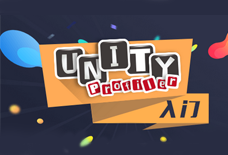

源码没有给课程 `img` 单独设置宽高，`course07.png` 以原始228×155px显示，宽度对应卡片228px。

`h3` 用20px内边距留出标题周围的空间，字号14px、正常字重、深色文字；底部 `p` 左右20px内边距，12px灰字；`span` 将“高级”改成橙色 `#ff7c2d`。

所有卡片都包在链接中。当前10项重复使用 `course07.png`，而该图片写的是 Unity Profiler，HTML 标题却重复为“Think PHP 5.0 博客系统实战项目演练”。这是资料中的图片与标题搭配差异，笔记保留原源码，不把它默默替换成设计稿里的 PHP 图片。

素材中部分其他课程图片并非228px宽，例如 `course01.png`、`pic.png` 为233px宽。若练习时替换图片，应重新检查是否超过卡片内容宽度；当前代码没有自动统一所有图片尺寸的规则。


### 6.4 clearfix 为什么加在 content 上

HTML 中的关键关系是：

```html
<div class="box wrapper">
    <div class="title">...</div>
    <div class="content clearfix">
        <ul>
            <!-- 浮动的课程 li -->
        </ul>
    </div>
</div>
```

这段仅用省略号展示已列出的结构关系，完整代码见6.1。

浮动 `li` 不会正常撑开普通流 `ul` 的自动高度。源码把 `clearfix` 放在包含这个 `ul` 的 `.content` 上，利用它末尾的伪元素 `clear: both` 避开内部浮动后撑出内容区高度，使后面的页脚排在整组卡片下方。

这里使用的是第06天的双伪元素方法，类加在需要获得内容高度的容器上，不是给每个浮动 `li` 增加一个类。它可以清除同一布局上下文中这组内部浮动的影响，不要求辅助伪元素必须与 `li` 成为直接兄弟。

验证时检查第5、10张是否位于每行末尾，再检查 `.content` 的高度与页脚位置。练习中暂时移除 `clearfix` 类，可以对照看到课程内容失去正常占位、后续页脚上移的影响；观察后恢复。


## 7. 页脚：通栏白底与左右内容

页脚在课程模块之后，外层负责背景和高度，内部继续复用版心。


### 7.1 页脚结构与当前文字

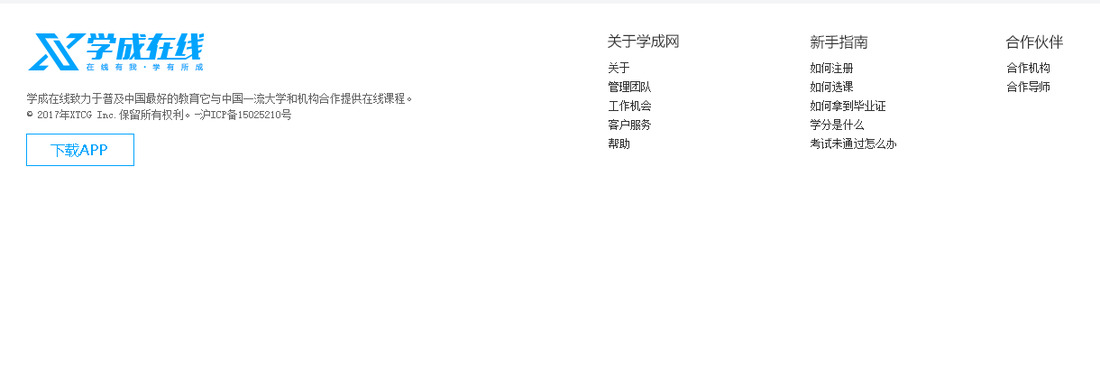

原 HTML：

```html
<!-- 版权 : 注意要清除浮动的影响, 课程的li 的 父级 -->
<!-- li都浮动了, 脱标, 撑不开父级的高度 -->
<div class="footer">
    <div class="wrapper">
        <div class="left">
            <img src="./images/logo.png" alt="">
            <p>学成在线致力于普及中国最好的教育它与中国一流大学和机构合作提供在线课程。<br>
                © 2017年XTCG Inc.保留所有权利。-沪ICP备15025210号</p>
            <a href="#">下载APP</a>
        </div>
        <div class="right">
            <dl>
                <dt>合作伙伴</dt>
                <dd><a href="#">合作机构</a></dd>
                <dd><a href="#">合作导师</a></dd>
            </dl>
            <dl>
                <dt>合作伙伴</dt>
                <dd><a href="#">合作机构</a></dd>
                <dd><a href="#">合作导师</a></dd>
            </dl>
            <dl>
                <dt>合作伙伴</dt>
                <dd><a href="#">合作机构</a></dd>
                <dd><a href="#">合作导师</a></dd>
            </dl>
        </div>
    </div>
</div>
```

左区包含标志、两行介绍与版权、下载 APP 链接；右区有3组 `dl`，每组由 `dt` 组标题与 `dd` 链接组成。

设计稿的右区分别是“关于学成网”“新手指南”“合作伙伴”，课堂源码却重复3组“合作伙伴”，每组只有“合作机构”“合作导师”。当前结构可用于练习列布局，不能描述成已完整填充设计稿页脚。


### 7.2 通栏尺寸与左右浮动

对应 CSS：

```css
/* 版权 */
.footer {
    margin-top: 40px;

    padding-top: 30px;

    height: 417px;
    background-color: #fff;
}

.footer .left {
    float: left;
}

.footer .left  p {
    margin: 20px 0 10px;
    font-size: 12px;
    color: #666;
}

.footer .left a {
    display: inline-block;
    width: 120px;
    height: 36px;
    border: 1px solid #00a4ff;
    text-align: center;
    line-height: 36px;
    font-size: 16px;
    color: #00a4ff;
}

.footer .right {
    float: right;
}

.footer .right dl {
    float: left;
    margin-left: 120px;
}
```

`.footer` 上外边距40px、上内边距30px、高417px、白色背景。它没有固定宽度，所以背景形成通栏；内部 `.wrapper` 将文字与图片限制在1200px版心。

全局内减模式下，上内边距30px包含在417px高度里。左区向左浮动，右区向右浮动；右区内部的各组 `dl` 再向左浮动，每组左外边距120px形成栏目间隔。

左区介绍的 `margin: 20px 0 10px` 表示上20px、左右0、下10px，12px灰字；HTML 的 `<br>` 固定分成两行。APP 链接转为行内块，可设置120×36px宽高、1px蓝色边框、居中文字。

本份 CSS 到 `.footer .right dl` 为止，没有另设页脚右侧 `dt`、`dd`、链接的字号、颜色和行高。右区会继续使用默认或继承样式，不要从设计图中反推一套不存在的声明。


### 7.3 页脚与上一组课程的浮动关系

原源码在页脚前提醒“课程的 li 都浮动了，撑不开父级高度”。这个提醒针对课程区域，而不是要求删除页脚内部的浮动。

课程 `.content` 通过 `clearfix` 正常占位后，页脚才能接在整组课程下面。页脚外盒子已经固定417px高度，即使内部 `.wrapper` 的子级也浮动，外层仍在普通流中提供既定高度。

当前源码没有给页脚内部 `.wrapper` 另加 `clearfix`。不要把所有浮动容器都描述成已经清除了影响，也不要仅因为页脚内容可见就认为内部版心已经由浮动孩子自动撑高。


## 8. 按原资料完成页面与核对

本日的学习重点是把已有属性组织成网页。从根目录开始，依照课件流程把源码中的区域逐一完成，再检查布局条件。


### 8.1 编写与观察顺序

1. 创建 `study/index.html`、`study/css/index.css` 与 `study/images`，先确认样式表、图片路径。
2. 写重置、内减模式、版心和背景，再完成头部各块。
3. 做横幅通栏与版心背景，加入左菜单和右课程表。
4. 做精品推荐条，检查浮动位置、分隔线与阴影。
5. 做课程标题和10张卡片，按1200px宽度验证每行5张。
6. 给课程内容容器加 `clearfix`，再写页脚，确认后续内容在课程下方。
7. 最后对照设计稿，核对尺寸、间距、文字与源码中的已实现范围。

以上是根据课件流程和源码顺序整理的练习步骤。本日原包没有额外作业答案，不把设计稿中尚未实现的其他模块扩写为课堂既有实现。


### 8.2 本页面需要检查的尺寸与状态

| 检查区域 | 按源码应观察到的结果 |
| --- | --- |
| 公共版心 | 宽1200px，普通流区域水平居中 |
| 头部 | 高42px，上下30px外边距；导航悬停显示底线 |
| 搜索宽度 | 412px外宽，410px内容宽；360px输入框与50px按钮同排 |
| 横幅 | 通栏深紫背景，高420px；内部1200×420px背景图 |
| 左菜单/右课程表 | 190×420px菜单；228×300px课程表距顶部50px |
| 兴趣推荐 | 高60px，距横幅8px，有灰色阴影 |
| 课程卡片 | 228×270px，每行5张，两排；第5、10项没有右外边距 |
| 课程内容与页脚 | `clearfix` 使课程容器有高度；页脚在课程之后 |
| 页脚 | 白底通栏，高417px，上内边距30px，左右内容同排 |

这些是依据原代码的核对预期，不是 Notebook 的程序执行结果。出现样式未加载、图片缺失、浮动换行或页脚上移时，先用 Chrome 查看对应元素的匹配样式和盒模型，再核对路径、总宽度与清除浮动的位置。

阅读完本篇，应能解释为什么搜索框不能把内部总宽写成412px、为什么卡片要使用 `5n`、为什么 `clearfix` 加在课程内容容器上，以及为什么通栏背景与版心要用不同盒子承担。
